# IP forward modelling time vs frequency domain

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import anemone
from copy import deepcopy

%matplotlib qt

SyntaxError: Missing parentheses in call to 'print'. Did you mean print('request:', request)? (reporter.py, line 79)

In [2]:
# make the system setup. 
# these components are in the experiment module.

from anemone.experiment import *

tx = Loop.square(3)
rx = Receiver(x=13)
waveform = Waveform.example()
recfilter = FilterChain([
    ButterworthFilter(2.4e5, 1),
    ButterworthFilter(6.2e5, 1),
    ButterworthFilter(4.5e5, 2)
])

In [37]:
# make the forward operators
# these are in the forwards module

from anemone.forwards import *

times = torch.logspace(-5, -3, 32)
fwrTD = IPForward(tx, rx, times, filterfunc=recfilter)

sampling_rate = 0.5e-9
times2 = torch.arange(times.min(), times.max(), sampling_rate)
times2 = torch.arange(sampling_rate, times.max(), sampling_rate)

fwrTD2 = IPForward(tx, rx, times2, filterfunc=recfilter)
# Calculate the relevant frequency axis
n = len(times2)
dt = times2[1] - times2[0]
frqs2= torch.fft.fftfreq(n, float(dt))

# frqs = (torch.arange(32)+1)*2e3
frqs = torch.logspace(3, 6, 51)
fwrFD = IPForwardFD(tx, rx, frqs, filterfunc=recfilter)

In [41]:
rho = torch.tensor([40, 80, 300], dtype=torch.double)
thickness = torch.tensor([20, 30], dtype=torch.double)
tau = torch.ones(3, dtype=torch.double)*1e-4
c = torch.ones(3, dtype=torch.double)*0.6
c[1] = 0.9
m = torch.tensor([0.2, 0.5, 0.9], dtype=torch.double)

dbdt = fwrTD(rho, tau,  m, c, thickness).real
dbdt2 = fwrTD2(rho, tau,  m, c, thickness).real
Bfrq2 = torch.fft.fft(dbdt2)*dt
Bfrq = fwrFD(rho, tau,  m, c, thickness)

In [40]:
times

tensor([1.0000e-05, 1.1602e-05, 1.3460e-05, 1.5615e-05, 1.8116e-05, 2.1017e-05,
        2.4384e-05, 2.8289e-05, 3.2819e-05, 3.8075e-05, 4.4173e-05, 5.1248e-05,
        5.9456e-05, 6.8978e-05, 8.0025e-05, 9.2841e-05, 1.0771e-04, 1.2496e-04,
        1.4497e-04, 1.6819e-04, 1.9513e-04, 2.2638e-04, 2.6264e-04, 3.0470e-04,
        3.5350e-04, 4.1011e-04, 4.7579e-04, 5.5200e-04, 6.4040e-04, 7.4296e-04,
        8.6195e-04, 1.0000e-03])

In [58]:
fig,axs = plt.subplots(1,2)
axs[0].loglog(times, dbdt, 'b')
axs[0].loglog(times,-dbdt, 'b--')
axs[0].loglog(times2, dbdt2, 'k')
axs[0].loglog(times2,-dbdt2, 'k--')



axs[0].set_aspect('equal')
axs[1].loglog(frqs, torch.abs(Bfrq), 'b')
plt.loglog(frqs2[0:len(frqs2)//2], torch.abs(Bfrq2[:len(frqs2)//2]), 'k')

In [51]:
plt.plot(frqs2)

In [57]:
plt.loglog(frqs2[0:len(frqs2)//2], torch.abs(Bfrq2[:len(frqs2)//2]), 'k')

In [6]:
from anemone.inversion import SmoothModelColeCole, FewLayerColeCole

In [49]:

fig,axs = plt.subplots(2,4, figsize=(12,6))
axmod = axs[:,:-2].flatten()

res_ref = 100
tau_ref = 1e-4
m_ref = 0.1
C_ref = 0.5


res_sweep = np.logspace(1, 3, 31)
m_sweep = np.logspace(-3, 0, 31)
tau_sweep = np.logspace(-6, -2, 21)
C_sweep = np.linspace(0.1, 1,10)


sweep_params = res_sweep

col = plt.cm.viridis(np.linspace(0, 1, len(sweep_params)))

for i,tmp in enumerate(sweep_params):
    
    
    # m_ref = tmp
    # tau_ref = tmp
    # C_ref = tmp
    res_ref = tmp

    #make the model 
    cmod = FewLayerColeCole([res_ref, res_ref], [tau_ref,tau_ref], [m_ref,m_ref], [C_ref, C_ref], [50])
   
    #forward models - freq and time domain
    Bf = fwrFD(*cmod.mod)
    dbdt = fwrTD(*cmod.mod).real

    axs[0,-2].loglog(frqs, torch.abs(Bf), label=f'{tmp}', color=col[i])
    axs[1,-2].loglog(times, dbdt, label=f'{tmp}', color=col[i])
    axs[1,-2].loglog(times, -dbdt, label=f'{tmp}', color=col[i],linestyle='--')

    dbdt = fwrTD(*cmod.mod).real
    axs[1,-2].loglog(times, dbdt, label=f'{r2}', color=col[i])
    axs[1,-2].loglog(times,-dbdt, label=f'{r2}', color=col[i],linestyle='--')

    if i == 0:  #grab the first data for references for comparisons with other models
        dbdt_ref = deepcopy(dbdt)
        Bf_ref = deepcopy(Bf)


    #difference plots
    axs[0,-1].plot(frqs, np.abs((torch.abs(Bf)-torch.abs(Bf_ref))/torch.abs(Bf_ref)*100), label=f'{r2}', color=col[i])
    axs[1,-1].plot(times, np.abs((dbdt-dbdt_ref)/dbdt_ref*100), label=f'{r2}', color=col[i])

    axs[0,-1].set_ylim([0,100])
    axs[1,-1].set_ylim([0,100])

    cmod.plot(axs=axmod, color=col[i])




for ax in axmod:
    ax.set_ylim(70,0)
axs[0,-1].set_title('FD % diff')
axs[1,-1].set_title('TD % diff')
axs[0,-2].set_title('FD data')
axs[1,-2].set_title('TD data')
axs[0,0].set_xscale('log')
axs[0,0].set_xlim([1,1000])
axs[0,1].set_xscale('log')
axs[0,1].set_xlim([1e-6,1e-2])
axs[1,0].set_xscale('log')
axs[1,0].set_xlim([1e-3,1])
axs[1,1].set_xlim([0,1])

axs[1,-1].set_xscale('log')




    


plt.tight_layout()

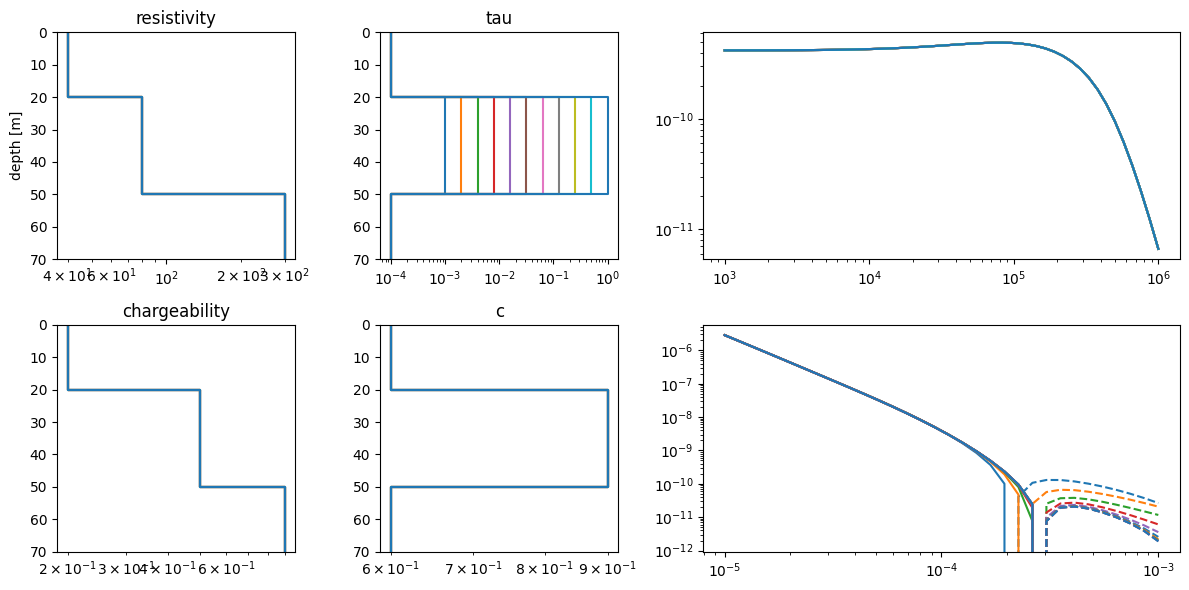

In [8]:
fig,axs = plt.subplots(2,3, figsize=(12,6), width_ratios=[1,1,2])
axmod = axs[:,:-1].flatten()

for i,tau2 in enumerate(np.logspace(-3, 0, 11)):
    cmod = FewLayerColeCole([40, 80, 300], [1e-4, tau2, 1e-4], [0.2, 0.5, 0.9], [0.6, 0.9, 0.6], [20, 30])
    Bf = fwrFD(*cmod.mod)
    axs[0,-1].loglog(frqs, torch.abs(Bf), label=f'{r2}')

    dbdt = fwrTD(*cmod.mod).real
    axs[1,-1].loglog(times, dbdt, f'C{i%5}', label=f'{r2}')
    axs[1,-1].loglog(times,-dbdt, f'C{i%5}--', label=f'{r2}')

    cmod.plot(axs=axmod)
    for ax in axmod:
        ax.set_ylim(70,0)
        ax.set_xscale('log')
plt.tight_layout()

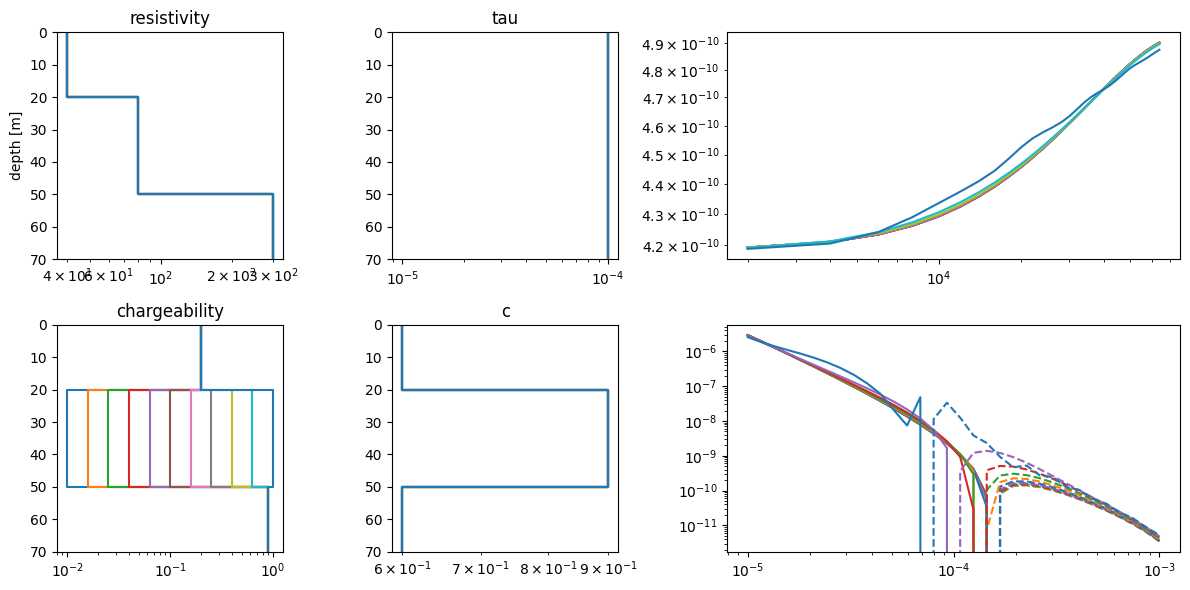

In [22]:
fig,axs = plt.subplots(2,3, figsize=(12,6), width_ratios=[1,1,2])
axmod = axs[:,:-1].flatten()

for i,m2 in enumerate(np.logspace(-2, 0, 11)):
    cmod = FewLayerColeCole([40, 80, 300], [1e-4, 1e-4, 1e-4], [0.2, m2, 0.9], [0.6, 0.9, 0.6], [20, 30])
    Bf = fwrFD(*cmod.mod)
    axs[0,-1].loglog(frqs, torch.abs(Bf), label=f'{r2}')

    dbdt = fwrTD(*cmod.mod).real
    axs[1,-1].loglog(times, dbdt, f'C{i%5}', label=f'{r2}')
    axs[1,-1].loglog(times,-dbdt, f'C{i%5}--', label=f'{r2}')

    cmod.plot(axs=axmod)
    for ax in axmod:
        ax.set_ylim(70,0)

        ax.set_xscale('log')
plt.tight_layout()

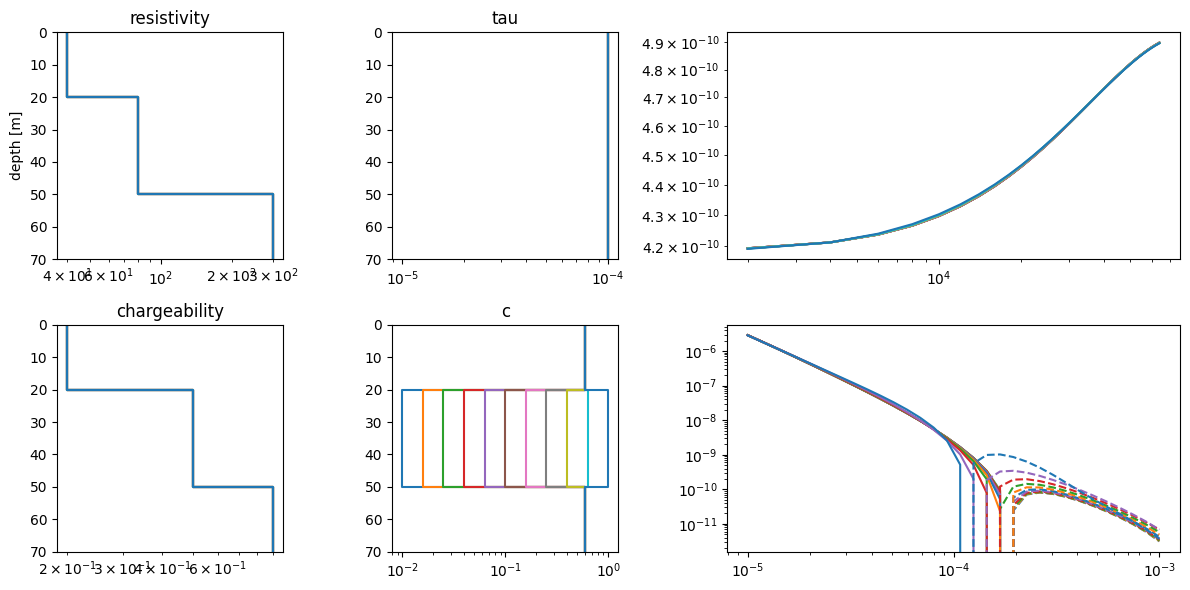

In [23]:
fig,axs = plt.subplots(2,3, figsize=(12,6), width_ratios=[1,1,2])
axmod = axs[:,:-1].flatten()

for i,c2 in enumerate(np.logspace(-2, 0, 11)):
    cmod = FewLayerColeCole([40, 80, 300], [1e-4, 1e-4, 1e-4], [0.2, 0.5, 0.9], [0.6, c2, 0.6], [20, 30])
    Bf = fwrFD(*cmod.mod)
    axs[0,-1].loglog(frqs, torch.abs(Bf), label=f'{r2}')

    dbdt = fwrTD(*cmod.mod).real
    axs[1,-1].loglog(times, dbdt, f'C{i%5}', label=f'{r2}')
    axs[1,-1].loglog(times,-dbdt, f'C{i%5}--', label=f'{r2}')

    cmod.plot(axs=axmod)
    for ax in axmod:
        ax.set_ylim(70,0)

        ax.set_xscale('log')
plt.tight_layout()

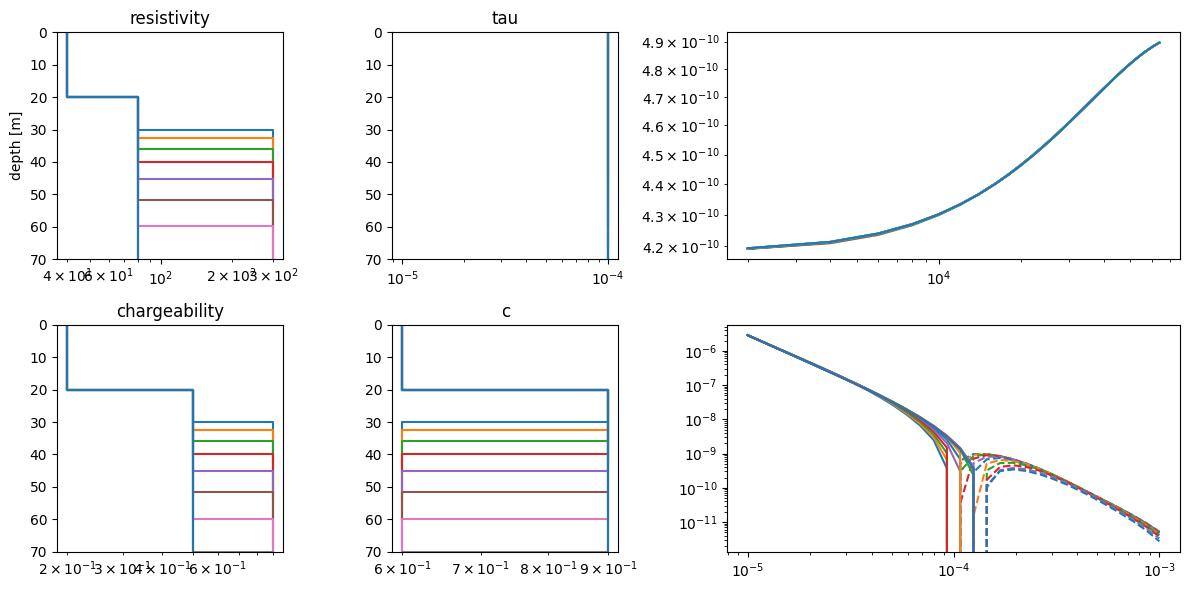

In [24]:
fig,axs = plt.subplots(2,3, figsize=(12,6), width_ratios=[1,1,2])
axmod = axs[:,:-1].flatten()

for i,thk2 in enumerate(np.logspace(1, 2, 11)):
    cmod = FewLayerColeCole([40, 80, 300], [1e-4, 1e-4, 1e-4], [0.2, 0.5, 0.9], [0.6, 0.9, 0.6], [20, thk2])
    Bf = fwrFD(*cmod.mod)
    axs[0,-1].loglog(frqs, torch.abs(Bf), label=f'{r2}')

    dbdt = fwrTD(*cmod.mod).real
    axs[1,-1].loglog(times, dbdt, f'C{i%5}', label=f'{r2}')
    axs[1,-1].loglog(times,-dbdt, f'C{i%5}--', label=f'{r2}')

    cmod.plot(axs=axmod)
    for ax in axmod:
        ax.set_ylim(70,0)

        ax.set_xscale('log')
plt.tight_layout()